# 03 — Hui2Vec

Hui2Vec (Belghith, Fournier-Viger, Jawadi, 2022) giữ nguyên khung của Trans2Vec, chỉ thay frequent itemset (FI) bằng **high-utility itemset (HUI)**. HUI là tập item có tổng lợi ích, tức số lượng × giá, đạt từ ngưỡng `minutil` trở lên:

- u(i, T) = p(i) × q(i, T)
- u(X, T) = Σ u(i, T) với i ∈ X
- u(X) = Σ u(X, T) trên các giao dịch T chứa X
- X là HUI nếu u(X) ≥ minutil

| Tên | Mô tả |
|---|---|
| TRANS-IT | Doc2Vec học từ item (giống notebook 02) |
| TRANS-HUI | Doc2Vec học từ các HUI của giao dịch |
| **Hui2Vec-IND** | trung bình vector của TRANS-IT và TRANS-HUI |
| **Hui2Vec-JOI** | Doc2Vec học từ item và HUI cùng lúc |

Cấu hình giữ giống hệt notebook 02 (PV-DBOW, d = 128, 50 epoch, Linear SVM C = 1, 10 lần chạy, cùng cách chia train/test). Token HUI được tách khỏi token item bằng tiền tố (`p1, p2, …`), như ở notebook 02. `minutil` được chọn bằng elbow method với cùng quy tắc như δ: đi từ ngưỡng cao xuống thấp, chọn ngưỡng đầu tiên mà số HUI tăng gấp đôi trở lên.

Giao dịch không chứa HUI nào được gán vector 0, đúng như mục 3.4 của bài.

In [4]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from utils import (DATA, PROCESSED, FIGURES, read_labeled, read_utility_db, mine_hui, mine_hui_maxlen2,
                   elbow, item_docs, pattern_docs, joint_docs, run_embedding_methods, log_results,
                   nice, score_table)

food_split = json.load(open(PROCESSED / "food_split.json"))
fm_split = json.load(open(PROCESSED / "foodmart_split.json"))


def plot_elbow(grid, counts, chosen, title, fname):
    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    ax.plot(grid, counts, marker="o")
    ax.scatter([chosen], [counts[grid.index(chosen)]], color="red", zorder=3, label="elbow")
    ax.set_xlabel("minutil")
    ax.set_ylabel("number of HUIs")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES / fname, dpi=150)
    plt.show()


def elbow_table(grid, counts, chosen, caption):
    tab = pd.DataFrame({"minutil": grid, "Số HUI": counts})
    tab["Được chọn"] = np.where(np.array(grid) == chosen, "←", "")
    return nice(tab, caption=caption)


def length_table(patterns, caption):
    lengths = pd.Series([len(h) for h in patterns]).value_counts().sort_index()
    return nice(pd.DataFrame({"Số item trong HUI": lengths.index, "Số HUI": lengths.to_numpy()}), caption=caption)

## 1. Foodmart utility — đúng dataset của bài Hui2Vec

HUI được khai thác bằng **EFIM**, đúng thuật toán bài báo dùng (bản cài đặt Python của thư viện PAMI). Utility là giá trị thật có sẵn trong `foodmart.txt`.

minutil,Số HUI,Được chọn
"12,000",261,
"10,000",428,
"9,000",546,
"8,000",769,
"7,000","1,903",←
"6,000","6,309",
"5,000","17,439",


Elbow method chọn minutil = 7,000


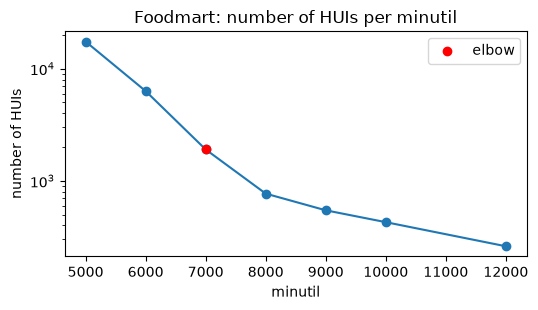

In [5]:
fm_file = DATA / "utility" / "foodmart.txt"
fm = read_utility_db(fm_file)
fm_trans = [t[0] for t in fm]
y_fm = pd.read_csv(PROCESSED / "foodmart_labels.csv")["label"].to_numpy()

fm_grid = [12000, 10000, 9000, 8000, 7000, 6000, 5000]
fm_huis = {m: mine_hui(fm_file, m) for m in fm_grid}
fm_counts = [len(fm_huis[m]) for m in fm_grid]
fm_minutil = elbow(fm_grid, fm_counts)

display(elbow_table(fm_grid, fm_counts, fm_minutil, "Foodmart: số HUI theo minutil"))
print(f"Elbow method chọn minutil = {fm_minutil:,}")
plot_elbow(fm_grid, fm_counts, fm_minutil, "Foodmart: number of HUIs per minutil", "foodmart_elbow_hui.png")

In [6]:
huis = list(fm_huis[fm_minutil].keys())
display(length_table(huis, "Foodmart: số HUI theo độ dài"))

fm_docs_it = item_docs(fm_trans)
fm_docs_hui = pattern_docs(fm_trans, huis)
fm_docs_joi = joint_docs(fm_docs_it, fm_docs_hui)
print(f"Giao dịch không chứa HUI nào (vector 0 ở TRANS-HUI): {sum(len(d) == 0 for d in fm_docs_hui):,} / {len(fm_trans):,}")

tr, te = np.array(fm_split["train"]), np.array(fm_split["test"])
fm_res = run_embedding_methods(fm_docs_it, fm_docs_hui, fm_docs_joi, y_fm, tr, te, pattern_name="HUI", family="Hui2Vec")
log_results(fm_res, "Foodmart", "Hui2Vec")
score_table(fm_res, "Foodmart — Hui2Vec")

Số item trong HUI,Số HUI
1,772
2,1
3,8
4,22
5,25
6,28
7,51
8,36
9,71
10,313


Giao dịch không chứa HUI nào (vector 0 ở TRANS-HUI): 375 / 4,141


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


10 lần chạy, 70 giây


Phương pháp,Accuracy (%),F1-macro (%),Số lần chạy
TRANS-IT,86.33 ± 0.28,86.32 ± 0.29,10
TRANS-HUI,78.26 ± 0.54,77.77 ± 0.55,10
Hui2Vec-IND,87.81 ± 0.42,87.79 ± 0.42,10
Hui2Vec-JOI,82.58 ± 0.77,82.36 ± 0.78,10


Bài Hui2Vec không công bố nhãn của Foodmart, nên ta không so con số với Bảng 6 của bài mà chỉ so Hui2Vec với Trans2Vec trên cùng một nhãn (notebook 04).

## 2. Food — dataset của bài Trans2Vec

Utility thật của Food lấy từ CSDL FoodMart ở notebook 01 (`processed/food_utility.txt`).

**Vì sao không chạy EFIM đầy đủ trên Food?** Food gộp mọi lần mua của một khách thành một giỏ, nên có giỏ rất dài (tới 250 item khác nhau). Hai con số sau cho thấy vấn đề:

In [7]:
food_db = read_utility_db(PROCESSED / "food_utility.txt")
food_trans = [t[0] for t in food_db]
food_tu = np.array([t[2] for t in food_db])
item_total = pd.Series({i: 0 for t in food_trans for i in t}, dtype="int64")
for items, utils_, _ in food_db:
    item_total[items] += utils_

nice(pd.DataFrame({
    "Chỉ số": ["Giỏ lớn nhất: số item", "Giỏ lớn nhất: utility",
               "Utility của item tốt nhất, cộng dồn trên toàn bộ dữ liệu"],
    "Giá trị": [max(map(len, food_trans)), int(food_tu.max()), int(item_total.max())],
}), caption="Food: vì sao EFIM đầy đủ không chạy được")

Chỉ số,Giá trị
Giỏ lớn nhất: số item,250
Giỏ lớn nhất: utility,"190,790"
"Utility của item tốt nhất, cộng dồn trên toàn bộ dữ liệu","103,904"


Utility của riêng giỏ lớn nhất cao gần gấp đôi utility của item tốt nhất cộng dồn trên toàn bộ dữ liệu. Hệ quả như sau:

- Nếu `minutil` cao hơn mức của item tốt nhất, gần như không có HUI nào.
- Nếu `minutil` thấp hơn, mọi tập con có utility đủ lớn **của riêng giỏ đó** đều thành HUI. Số tập con như vậy lên tới hàng tỉ, và EFIM không chạy xong.

Vì vậy, trên Food ta giới hạn **HUI tối đa 2 item**. Cách này giống ràng buộc độ dài pattern của thuật toán FHM+ trong SPMF, và tương đương với FI của Food ở δ = 0,2% (gần như chỉ gồm FI 1 và 2 item). HUI độ dài ≤ 2 được tính chính xác bằng phép nhân ma trận thưa (`mine_hui_maxlen2` trong `utils.py`).

minutil,Số HUI,Được chọn
"50,000",612,
"40,000",853,
"30,000","1,147",
"25,000","1,269",
"20,000","1,568",
"17,500","2,175",
"15,000","4,313",
"12,500","11,899",←
"10,000","36,349",


Elbow method chọn minutil = 12,500


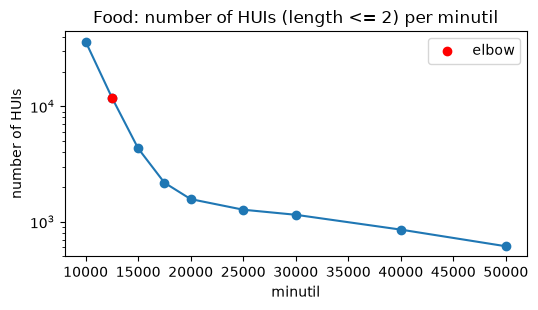

In [8]:
food_grid = [50000, 40000, 30000, 25000, 20000, 17500, 15000, 12500, 10000]
food_hui_by = {m: mine_hui_maxlen2(PROCESSED / "food_utility.txt", m) for m in food_grid}
food_counts = [len(food_hui_by[m]) for m in food_grid]
food_minutil = elbow(food_grid, food_counts)

display(elbow_table(food_grid, food_counts, food_minutil, "Food: số HUI (tối đa 2 item) theo minutil"))
print(f"Elbow method chọn minutil = {food_minutil:,}")
plot_elbow(food_grid, food_counts, food_minutil, "Food: number of HUIs (length <= 2) per minutil", "food_elbow_hui.png")

In [9]:
food_huis = list(food_hui_by[food_minutil].keys())
display(length_table(food_huis, "Food: số HUI theo độ dài"))

docs_it, y_food = read_labeled(DATA / "food" / "food.txt")     # same item tokens as notebook 02
food_docs_hui = pattern_docs(food_trans, food_huis)
food_docs_joi = joint_docs(docs_it, food_docs_hui)
print(f"Giao dịch không chứa HUI nào: {sum(len(d) == 0 for d in food_docs_hui):,} / {len(food_trans):,}")

tr, te = np.array(food_split["train"]), np.array(food_split["test"])
food_res = run_embedding_methods(docs_it, food_docs_hui, food_docs_joi, y_food, tr, te, pattern_name="HUI", family="Hui2Vec")
log_results(food_res, "Food", "Hui2Vec")
json.dump({"food_minutil": int(food_minutil), "foodmart_minutil": int(fm_minutil)}, open(PROCESSED / "hui_thresholds.json", "w"))
score_table(food_res, "Food — Hui2Vec")

Số item trong HUI,Số HUI
1,"1,498"
2,"10,401"


Giao dịch không chứa HUI nào: 0 / 4,000


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

10 lần chạy, 136 giây


Phương pháp,Accuracy (%),F1-macro (%),Số lần chạy
TRANS-IT,67.55 ± 0.94,67.49 ± 0.93,10
TRANS-HUI,69.75 ± 0.79,69.62 ± 0.82,10
Hui2Vec-IND,67.66 ± 1.50,67.59 ± 1.51,10
Hui2Vec-JOI,70.34 ± 0.65,70.31 ± 0.65,10


Kết quả của hai dataset đã được ghi vào `results.csv`. So sánh với Trans2Vec nằm ở notebook 04.